In [ ]:
!pip install -q transformers datasets torch torchvision evaluate accelerate

## Dataset Preparation & Preprocessing

In [ ]:
from datasets import load_dataset
from transformers import AutoImageProcessor
from torchvision.transforms import Compose, Resize, ToTensor, Normalize

# 1. Load the ENTIRE dataset and perform the stratified split
full_dataset = load_dataset("maveriq/tobacco3482", split="train")
dataset = full_dataset.train_test_split(test_size=0.2, stratify_by_column="label", seed=42)

# 2. Extract the categories to map predictions back to readable text
labels = dataset["train"].features["label"].names
label2id = {label: str(i) for i, label in enumerate(labels)}
id2label = {str(i): label for i, label in enumerate(labels)}

# 3. Initialize the image processor
processor = AutoImageProcessor.from_pretrained("microsoft/dit-base")
size = (processor.size["height"], processor.size["width"])

# 4. Define the image transformation pipeline
_transforms = Compose([
    Resize(size),
    ToTensor(),
    Normalize(mean=processor.image_mean, std=processor.image_std)
])

def apply_transforms(examples):
    # This creates the 'pixel_values' key required by the trainer
    examples["pixel_values"] = [_transforms(img.convert("RGB")) for img in examples["image"]]
    return examples

# 5. Attach the transformations to the dataset
dataset.set_transform(apply_transforms)

print("Dataset prepared and transformations applied successfully!")

Dataset prepared and transformations applied successfully!


## Model Initialization & Training Loop

In [ ]:
import evaluate
import numpy as np
from transformers import AutoModelForImageClassification, TrainingArguments, Trainer

# Initializing a base model with a fresh, untrained classification head
model = AutoModelForImageClassification.from_pretrained(
    "microsoft/dit-base",
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return accuracy.compute(predictions=predictions, references=labels)

training_args = TrainingArguments(
    output_dir="./my_document_classifier",
    remove_unused_columns=False,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=8,   # Adjust based on Colab GPU memory
    gradient_accumulation_steps=4,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    metric_for_best_model="accuracy",
    load_best_model_at_end=True,
)

# Initializing the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["test"],
    compute_metrics=compute_metrics,
)

print("Starting model training...")
trainer.train()

Loading weights:   0%|          | 0/209 [00:00<?, ?it/s]

[transformers] BeitForImageClassification LOAD REPORT from: microsoft/dit-base
Key                          | Status     | 
-----------------------------+------------+-
layernorm.bias               | UNEXPECTED | 
lm_head.bias                 | UNEXPECTED | 
layernorm.weight             | UNEXPECTED | 
lm_head.weight               | UNEXPECTED | 
beit.pooler.layernorm.weight | MISSING    | 
beit.pooler.layernorm.bias   | MISSING    | 
classifier.bias              | MISSING    | 
classifier.weight            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting model training...


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.411549,0.889527
2,No log,0.247518,0.936872
3,No log,0.226728,0.942611


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['beit.layers.0.lambda_1', 'beit.layers.0.lambda_2', 'beit.layers.0.attention.q_proj.weight', 'beit.layers.0.attention.q_proj.bias', 'beit.layers.0.attention.k_proj.weight', 'beit.layers.0.attention.v_proj.weight', 'beit.layers.0.attention.v_proj.bias', 'beit.layers.0.attention.o_proj.weight', 'beit.layers.0.attention.o_proj.bias', 'beit.layers.0.layernorm_before.weight', 'beit.layers.0.layernorm_before.bias', 'beit.layers.0.layernorm_after.weight', 'beit.layers.0.layernorm_after.bias', 'beit.layers.0.mlp.fc1.weight', 'beit.layers.0.mlp.fc1.bias', 'beit.layers.0.mlp.fc2.weight', 'beit.layers.0.mlp.fc2.bias', 'beit.layers.1.lambda_1', 'beit.layers.1.lambda_2', 'beit.layers.1.attention.q_proj.weight', 'beit.layers.1.attention.q_proj.bias', 'beit.layers.1.attention.k_proj.weight', 'beit.layers.1.attention.v_proj.weight', 'beit.layers.1.attention.v_proj.bias', 'beit.layers.1.attention.o_proj.weight', 'beit.layers.1.atte

TrainOutput(global_step=264, training_loss=2.4437255859375, metrics={'train_runtime': 1031.5762, 'train_samples_per_second': 8.099, 'train_steps_per_second': 0.256, 'total_flos': 6.475673349798912e+17, 'train_loss': 2.4437255859375, 'epoch': 3.0})

In [ ]:
trainer.save_model("./my_document_classifier")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Evaluating final model on the test dataset...



FINAL CLASSIFICATION REPORT (Copy to your PDF)
              precision    recall  f1-score   support

        ADVE       1.00      0.98      0.99        46
       Email       0.99      1.00      1.00       120
        Form       0.90      0.98      0.94        86
      Letter       0.93      0.99      0.96       114
        Memo       0.98      0.97      0.98       124
        News       0.97      1.00      0.99        38
        Note       0.94      0.85      0.89        40
      Report       0.84      0.81      0.83        53
      Resume       0.87      0.83      0.85        24
  Scientific       0.89      0.77      0.82        52

    accuracy                           0.94       697
   macro avg       0.93      0.92      0.92       697
weighted avg       0.94      0.94      0.94       697


Generating Confusion Matrix...


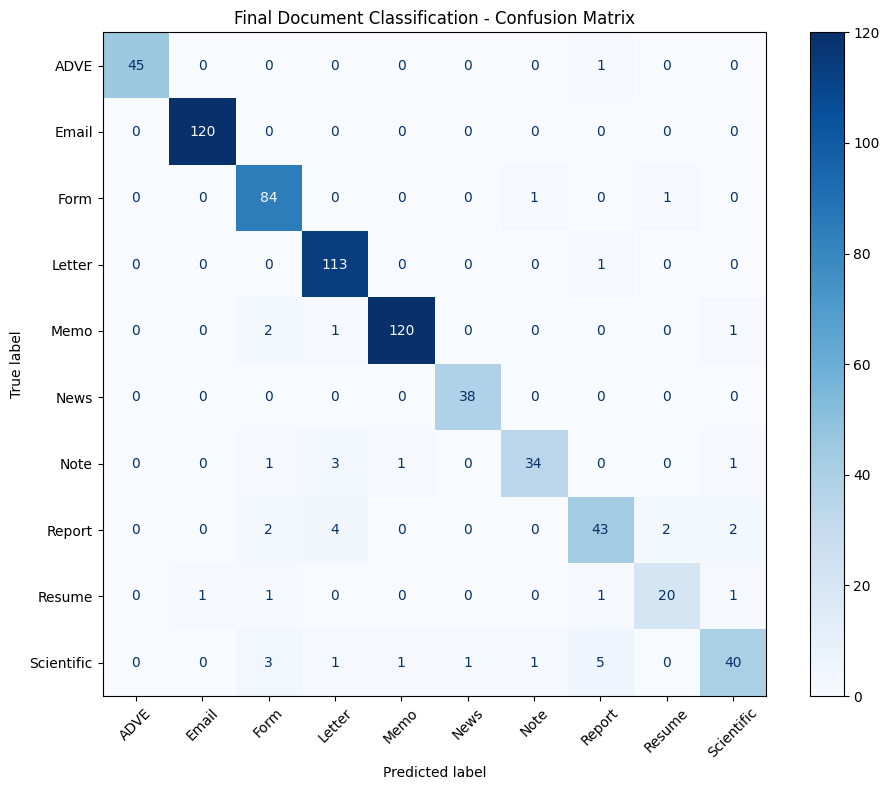

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Evaluating final model on the test dataset...")
test_results = trainer.predict(dataset["test"])

y_true = test_results.label_ids
y_pred = np.argmax(test_results.predictions, axis=-1)

# Generate Classification Report
print("\n" + "="*50)
print("FINAL CLASSIFICATION REPORT")
print("="*50)
report = classification_report(y_true, y_pred, target_names=label_names)
print(report)

# Generate and Plot Confusion Matrix
print("\nGenerating Confusion Matrix...")
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title("Final Document Classification - Confusion Matrix")
plt.tight_layout()
plt.savefig("final_confusion_matrix.png", dpi=300)
plt.show()

In [ ]:
!zip -r my_document_classifier.zip my_document_classifier/

  adding: my_document_classifier/ (stored 0%)
  adding: my_document_classifier/config.json (deflated 60%)
  adding: my_document_classifier/model.safetensors (deflated 7%)
  adding: my_document_classifier/checkpoint-88/ (stored 0%)
  adding: my_document_classifier/checkpoint-88/config.json (deflated 60%)
  adding: my_document_classifier/checkpoint-88/model.safetensors (deflated 7%)
  adding: my_document_classifier/checkpoint-88/optimizer.pt (deflated 7%)
  adding: my_document_classifier/checkpoint-88/scheduler.pt (deflated 61%)
  adding: my_document_classifier/checkpoint-88/training_args.bin (deflated 53%)
  adding: my_document_classifier/checkpoint-88/trainer_state.json (deflated 56%)
  adding: my_document_classifier/checkpoint-88/rng_state.pth (deflated 26%)
  adding: my_document_classifier/checkpoint-264/ (stored 0%)
  adding: my_document_classifier/checkpoint-264/config.json (deflated 60%)
  adding: my_document_classifier/checkpoint-264/model.safetensors (deflated 7%)
  adding: my_d